In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# prepare the images

In [2]:
import os, shutil
import numpy as np, pandas as pd
from PIL import Image

research = '/content/drive/MyDrive/Research'
out_dir  = f'{research}/outputs/model1'
os.makedirs(out_dir, exist_ok=True)
cache_drive = f'{out_dir}/cache_224.npz'
cache_local = '/content/cache_224.npz'
SIZE = 224

def load_gray_square(path, size=SIZE):
    im = Image.open(path)
    im.load()                                                 # forces full read; fails on broken files
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        arr = np.array(im).astype(np.float32)
        arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-6) * 255
        im = Image.fromarray(arr.astype(np.uint8))
    im = im.convert('L')
    w, h = im.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0)
    canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.array(canvas.resize((size, size), Image.BILINEAR), dtype=np.uint8)

if os.path.exists(cache_drive):
    shutil.copy(cache_drive, cache_local)
    print('Loaded existing prepared images from Drive.')
else:
    df = pd.read_csv(f'{research}/outputs/manifest_split.csv')
    df = df[df.split != 'not_used'].reset_index(drop=True)
    X = np.zeros((len(df), SIZE, SIZE), dtype=np.uint8)
    ok = np.ones(len(df), dtype=bool)
    broken = []
    for i, p in enumerate(df.path):
        try:
            X[i] = load_gray_square(p)
        except Exception as e:
            ok[i] = False
            broken.append((df.filename[i], df.label[i], str(e)[:60]))
        if i % 500 == 0: print(f'{i}/{len(df)} images prepared')

    print(f'\nBroken files skipped: {len(broken)}')
    for b in broken: print('   ', b)
    pd.DataFrame(broken, columns=['filename', 'label', 'error']).to_csv(f'{out_dir}/broken_files.csv', index=False)

    df, X = df[ok].reset_index(drop=True), X[ok]
    y = (df.label == 'X_RAY').astype(np.int64).values
    np.savez_compressed(cache_local, X=X, y=y, split=df.split.values,
                        source=df.source.values, path=df.path.values)
    shutil.copy(cache_local, cache_drive)
    print('Done. Saved prepared images to', cache_drive)

d = np.load(cache_local, allow_pickle=True)
print('Images:', d['X'].shape, '| X_RAY:', d['y'].sum(), '| NON_XRAY:', (d['y'] == 0).sum())

Loaded existing prepared images from Drive.
Images: (3502, 224, 224) | X_RAY: 1678 | NON_XRAY: 1824


Using: cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 142MB/s]


Epoch  1 | train loss 0.1084 | val loss 0.1013 | val acc 0.9584 | val AUC 1.0000 | 13s
   -> saved best model
Epoch  2 | train loss 0.0074 | val loss 0.0179 | val acc 0.9981 | val AUC 1.0000 | 11s
   -> saved best model
Epoch  3 | train loss 0.0017 | val loss 0.0056 | val acc 1.0000 | val AUC 1.0000 | 11s
   -> saved best model
Epoch  4 | train loss 0.0010 | val loss 0.0028 | val acc 1.0000 | val AUC 1.0000 | 11s
   -> saved best model
Epoch  5 | train loss 0.0003 | val loss 0.0012 | val acc 1.0000 | val AUC 1.0000 | 11s
   -> saved best model
Epoch  6 | train loss 0.0016 | val loss 0.0058 | val acc 0.9962 | val AUC 1.0000 | 11s
Epoch  7 | train loss 0.0088 | val loss 0.0031 | val acc 0.9981 | val AUC 1.0000 | 11s
Epoch  8 | train loss 0.0008 | val loss 0.0009 | val acc 1.0000 | val AUC 1.0000 | 11s
   -> saved best model
Epoch  9 | train loss 0.0012 | val loss 0.0029 | val acc 0.9981 | val AUC 1.0000 | 12s
Epoch 10 | train loss 0.0007 | val loss 0.0003 | val acc 1.0000 | val AUC 1.000

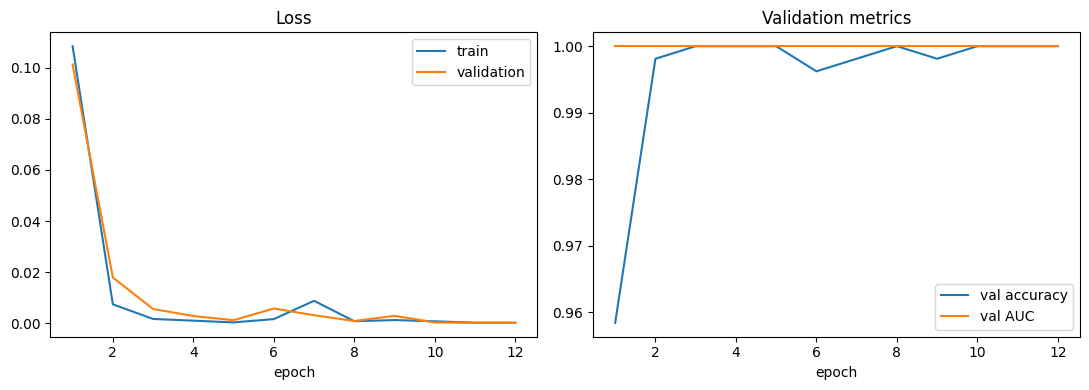

In [3]:
import torch, torch.nn as nn, numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2 as T
from sklearn.metrics import roc_auc_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)
torch.manual_seed(42); np.random.seed(42)

d = np.load('/content/cache_224.npz', allow_pickle=True)
X, y, split = d['X'], d['y'], d['split']
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

train_aug = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), antialias=True),
    T.RandomRotation(10),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.15, contrast=0.15),
])

class ImageSet(Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = idx, train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = torch.from_numpy(X[j]).unsqueeze(0)            # 1 x 224 x 224
        if self.train:
            img = train_aug(img)
        img = img.float().div(255).repeat(3, 1, 1)           # grayscale -> 3 channels
        return (img - mean) / std, int(y[j])

idx = {s: np.where(split == s)[0] for s in ['train', 'val', 'test']}
train_dl = DataLoader(ImageSet(idx['train'], True),  batch_size=32, shuffle=True,  num_workers=2)
val_dl   = DataLoader(ImageSet(idx['val'],   False), batch_size=64, shuffle=False, num_workers=2)

model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)   # 2 classes
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

def run_eval(dl):
    model.eval(); losses, probs, labels = [], [], []
    with torch.no_grad():
        for xb, yb in dl:
            out = model(xb.to(device))
            losses.append(loss_fn(out, yb.to(device)).item() * len(yb))
            probs.append(torch.softmax(out, 1)[:, 1].cpu()); labels.append(yb)
    p, l = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return sum(losses) / len(l), p, l

EPOCHS, PATIENCE = 12, 3
best_loss, wait, history = 1e9, 0, []
save_path = '/content/drive/MyDrive/Research/outputs/model1/mobilenetv3_model1_best.pt'

for ep in range(1, EPOCHS + 1):
    t0 = time.time(); model.train(); tl, n = 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
        tl += loss.item() * len(yb); n += len(yb)
    vl, vp, vy = run_eval(val_dl)
    vacc, vauc = ((vp >= 0.5) == vy).mean(), roc_auc_score(vy, vp)
    history.append(dict(epoch=ep, train_loss=tl / n, val_loss=vl, val_acc=vacc, val_auc=vauc))
    print(f'Epoch {ep:2d} | train loss {tl/n:.4f} | val loss {vl:.4f} | '
          f'val acc {vacc:.4f} | val AUC {vauc:.4f} | {time.time()-t0:.0f}s')
    if vl < best_loss:
        best_loss, wait = vl, 0
        torch.save(model.state_dict(), save_path); print('   -> saved best model')
    else:
        wait += 1
        if wait >= PATIENCE:
            print('Stopping early: validation loss stopped improving.'); break

h = pd.DataFrame(history)
h.to_csv('/content/drive/MyDrive/Research/outputs/model1/training_history.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc, label='val accuracy'); ax[1].plot(h.epoch, h.val_auc, label='val AUC')
ax[1].set_title('Validation metrics'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Research/outputs/model1/training_curves.png', dpi=150)
plt.show()

# Evaluate

test_images              542
accuracy                 1.0
precision_xray           1.0
recall_xray              1.0
f1_xray                  1.0
roc_auc                  1.0
FAR_nonxray_accepted     0.0
FRR_xray_rejected        0.0
TP                       269
TN                       273
FP                       0
FN                       0


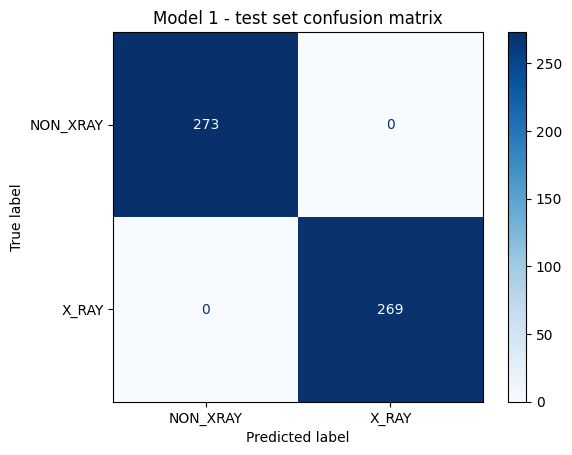


Per-source results (test set):
                     images  errors  accuracy
source                                       
animals_512_unknown      47       0       1.0
brain_mri_kaggle         50       0       1.0
ct_organamnist           50       0       1.0
grazpedwri               53       0       1.0
hospital                 68       0       1.0
knee_kaggle              92       0       1.0
other_nonxray             4       0       1.0
other_xray               20       0       1.0
unknown_IMG              36       0       1.0
us_breastmnist           48       0       1.0
vegetables_unknown       26       0       1.0
vehicles_unknown         48       0       1.0

Misclassified test images: 0


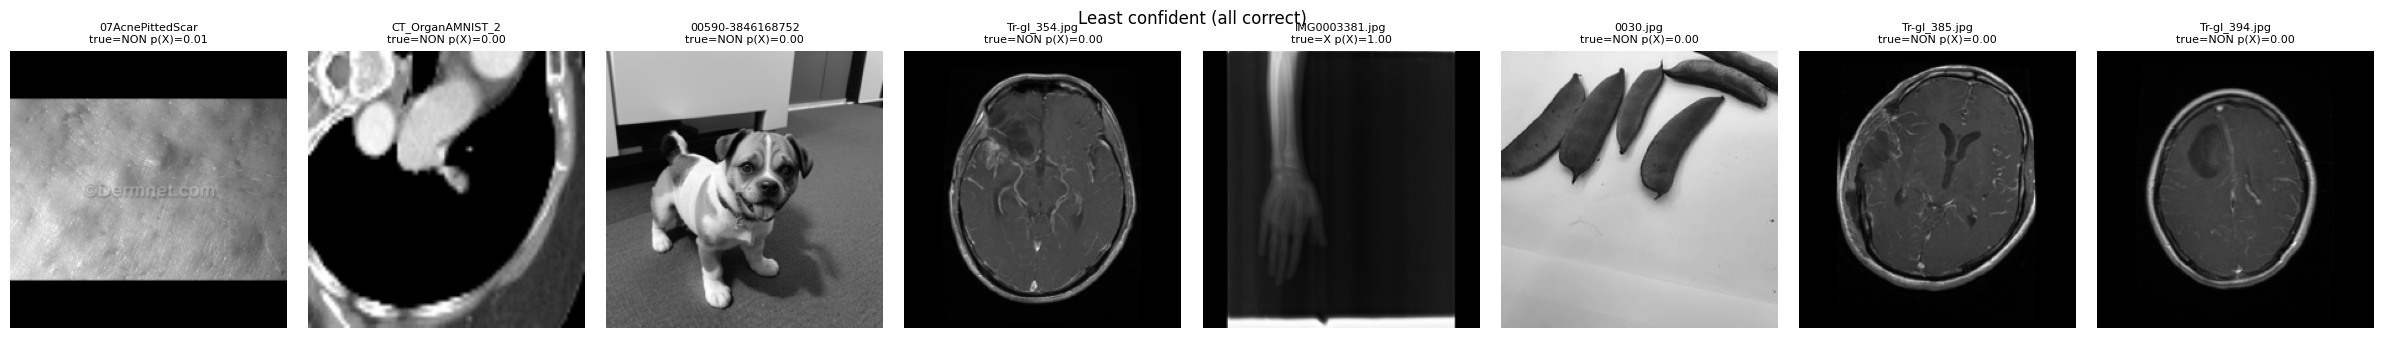


Model size: 17.0 MB | Parameters: 4.20 M | Speed: 6.33 ms per image on cuda
Saved all results to /content/drive/MyDrive/Research/outputs/model1


In [4]:
import torch, torch.nn as nn, numpy as np, pandas as pd, time, os, json
import matplotlib.pyplot as plt
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
out = '/content/drive/MyDrive/Research/outputs/model1'
d = np.load('/content/cache_224.npz', allow_pickle=True)
X, y, split, source, path = d['X'], d['y'], d['split'], d['source'], d['path']
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prep(imgs):                                   # N x 224 x 224 uint8 -> model input
    t = torch.from_numpy(imgs).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (t - mean) / std

# ---- 1. Load the best saved model ----
model = models.mobilenet_v3_large()
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
model.load_state_dict(torch.load(f'{out}/mobilenetv3_model1_best.pt', map_location=device))
model = model.to(device).eval()

# ---- 2. Predict on the TEST set (used for the first and only time) ----
ti = np.where(split == 'test')[0]
probs = []
with torch.no_grad():
    for k in range(0, len(ti), 64):
        probs.append(torch.softmax(model(prep(X[ti[k:k+64]]).to(device)), 1)[:, 1].cpu().numpy())
p = np.concatenate(probs)              # probability of X_RAY
yt = y[ti]
pred = (p >= 0.5).astype(int)          # threshold 0.5

# ---- 3. Metrics ----
tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
metrics = {
    'test_images': int(len(ti)),
    'accuracy':  round(accuracy_score(yt, pred), 4),
    'precision_xray': round(precision_score(yt, pred, zero_division=0), 4),
    'recall_xray':    round(recall_score(yt, pred, zero_division=0), 4),
    'f1_xray':        round(f1_score(yt, pred, zero_division=0), 4),
    'roc_auc':        round(roc_auc_score(yt, p), 4),
    'FAR_nonxray_accepted': round(fp / (fp + tn), 4),
    'FRR_xray_rejected':    round(fn / (fn + tp), 4),
    'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
}
for k, v in metrics.items(): print(f'{k:24s} {v}')

cm = ConfusionMatrixDisplay(confusion_matrix(yt, pred, labels=[0, 1]),
                            display_labels=['NON_XRAY', 'X_RAY'])
cm.plot(cmap='Blues', values_format='d'); plt.title('Model 1 - test set confusion matrix')
plt.savefig(f'{out}/confusion_matrix_test.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 4. Results per source ----
res = pd.DataFrame({'path': path[ti], 'source': source[ti], 'true': yt, 'prob_xray': p, 'pred': pred})
res['correct'] = res.true == res.pred
per_src = res.groupby('source').agg(images=('correct', 'size'), errors=('correct', lambda c: int((~c).sum())),
                                    accuracy=('correct', 'mean')).round(4)
print('\nPer-source results (test set):'); print(per_src.to_string())
res.to_csv(f'{out}/test_predictions.csv', index=False)
per_src.to_csv(f'{out}/test_per_source.csv')

# ---- 5. Wrong predictions; if none, show the least confident ones ----
wrong = res[~res.correct]
print(f'\nMisclassified test images: {len(wrong)}')
show = wrong if len(wrong) else res.assign(conf=(res.prob_xray - 0.5).abs()).nsmallest(8, 'conf')
title = 'Misclassified' if len(wrong) else 'Least confident (all correct)'
n = min(len(show), 8)
if n:
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.4)); axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, show.head(n).iterrows()):
        j = np.where(path == r.path)[0][0]
        ax.imshow(X[j], cmap='gray'); ax.axis('off')
        ax.set_title(f"{os.path.basename(r.path)[:16]}\ntrue={'X' if r.true else 'NON'} p(X)={r.prob_xray:.2f}", fontsize=8)
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f'{out}/test_examples.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 6. Model size and speed ----
size_mb = os.path.getsize(f'{out}/mobilenetv3_model1_best.pt') / 1e6
params = sum(t.numel() for t in model.parameters()) / 1e6
one = prep(X[ti[:1]]).to(device)
with torch.no_grad():
    for _ in range(10): model(one)                       # warm-up
    if device == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(100): model(one)
    if device == 'cuda': torch.cuda.synchronize()
ms = (time.time() - t0) / 100 * 1000
metrics.update(model_size_mb=round(size_mb, 1), parameters_millions=round(params, 2),
               ms_per_image=round(ms, 2), device=device)
print(f'\nModel size: {size_mb:.1f} MB | Parameters: {params:.2f} M | Speed: {ms:.2f} ms per image on {device}')
json.dump(metrics, open(f'{out}/test_metrics.json', 'w'), indent=2)
print('Saved all results to', out)

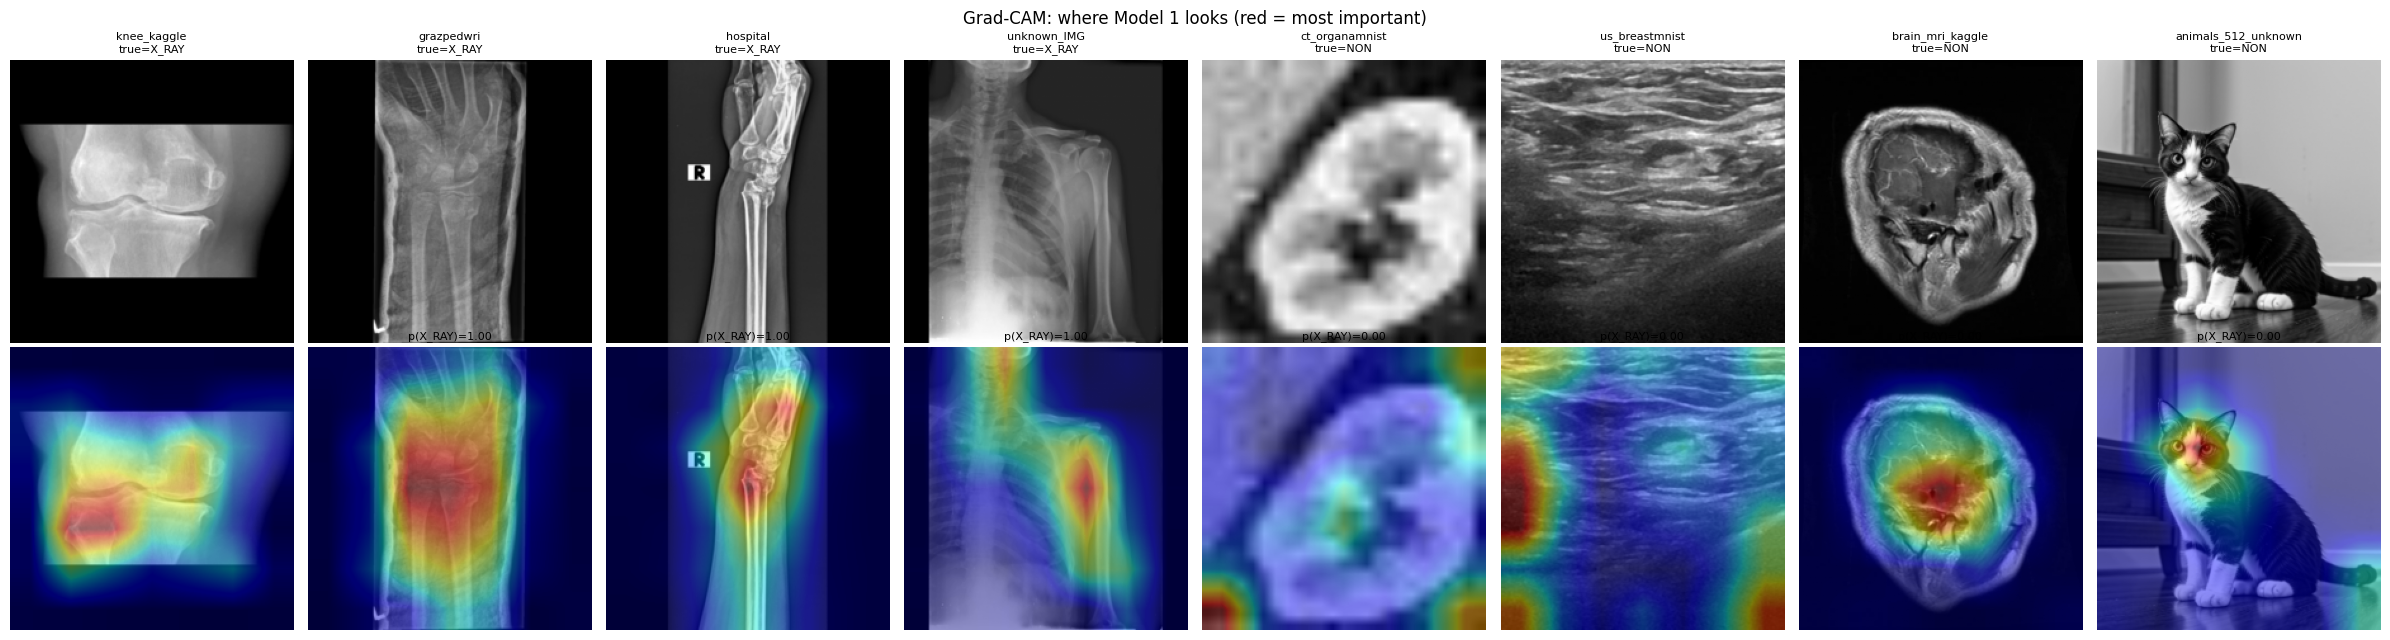

In [5]:
import torch, numpy as np, matplotlib.pyplot as plt

acts, grads = {}, {}
layer = model.features[-1]                                  # last convolution block
def fwd_hook(m, i, o):
    acts['a'] = o
    o.register_hook(lambda g: grads.__setitem__('g', g))
hook = layer.register_forward_hook(fwd_hook)

def gradcam(img):                                           # img: 224 x 224 uint8
    model.zero_grad()
    out = model(prep(img[None]).to(device))
    cls = out.argmax(1).item()
    out[0, cls].backward()
    a, g = acts['a'][0], grads['g'][0]                      # feature maps and their gradients
    cam = torch.relu((g.mean((1, 2))[:, None, None] * a).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = torch.nn.functional.interpolate(cam[None, None], size=(224, 224), mode='bilinear')[0, 0]
    return cam.detach().cpu().numpy(), torch.softmax(out, 1)[0, 1].item()

# pick 1 test image from each of 8 different sources
rng = np.random.default_rng(0)
picks = []
for s in ['knee_kaggle', 'grazpedwri', 'hospital', 'unknown_IMG',
          'ct_organamnist', 'us_breastmnist', 'brain_mri_kaggle', 'animals_512_unknown']:
    cand = ti[source[ti] == s]
    if len(cand): picks.append(rng.choice(cand))

fig, axes = plt.subplots(2, len(picks), figsize=(3 * len(picks), 6.5))
for k, j in enumerate(picks):
    cam, px = gradcam(X[j])
    axes[0, k].imshow(X[j], cmap='gray'); axes[0, k].axis('off')
    axes[0, k].set_title(f"{source[j]}\ntrue={'X_RAY' if y[j] else 'NON'}", fontsize=8)
    axes[1, k].imshow(X[j], cmap='gray'); axes[1, k].imshow(cam, cmap='jet', alpha=0.45)
    axes[1, k].axis('off'); axes[1, k].set_title(f'p(X_RAY)={px:.2f}', fontsize=8)
plt.suptitle('Grad-CAM: where Model 1 looks (red = most important)')
plt.tight_layout()
plt.savefig(f'{out}/gradcam_examples.png', dpi=150, bbox_inches='tight'); plt.show()
hook.remove()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.8 MB/s eta 0:00:00


100%|██████████| 214M/214M [03:27<00:00, 1.03MB/s]
100%|██████████| 760M/760M [07:16<00:00, 1.74MB/s]
100%|██████████| 128M/128M [01:58<00:00, 1.08MB/s]
100%|██████████| 345M/345M [00:16<00:00, 21.1MB/s]
100%|██████████| 502/502 [00:00<00:00, 863kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 10.1MB/s]


                       group expected  images  predicted_xray  mean_prob_xray  correct_%
   chest_xray_PneumoniaMNIST    X_RAY      60              39           0.635       65.0
      CT_coronal_OrganCMNIST NON_XRAY      50               0           0.004      100.0
    retina_photo_RetinaMNIST NON_XRAY      40               9           0.305       77.5
     flower_photo_Flowers102 NON_XRAY      40               1           0.023       97.5
     text_document_synthetic NON_XRAY      20               0           0.024      100.0
          EDGE_inverted_xray  unclear      20              19           0.921        NaN
EDGE_photo_of_xray_simulated  unclear      20              20           0.994        NaN


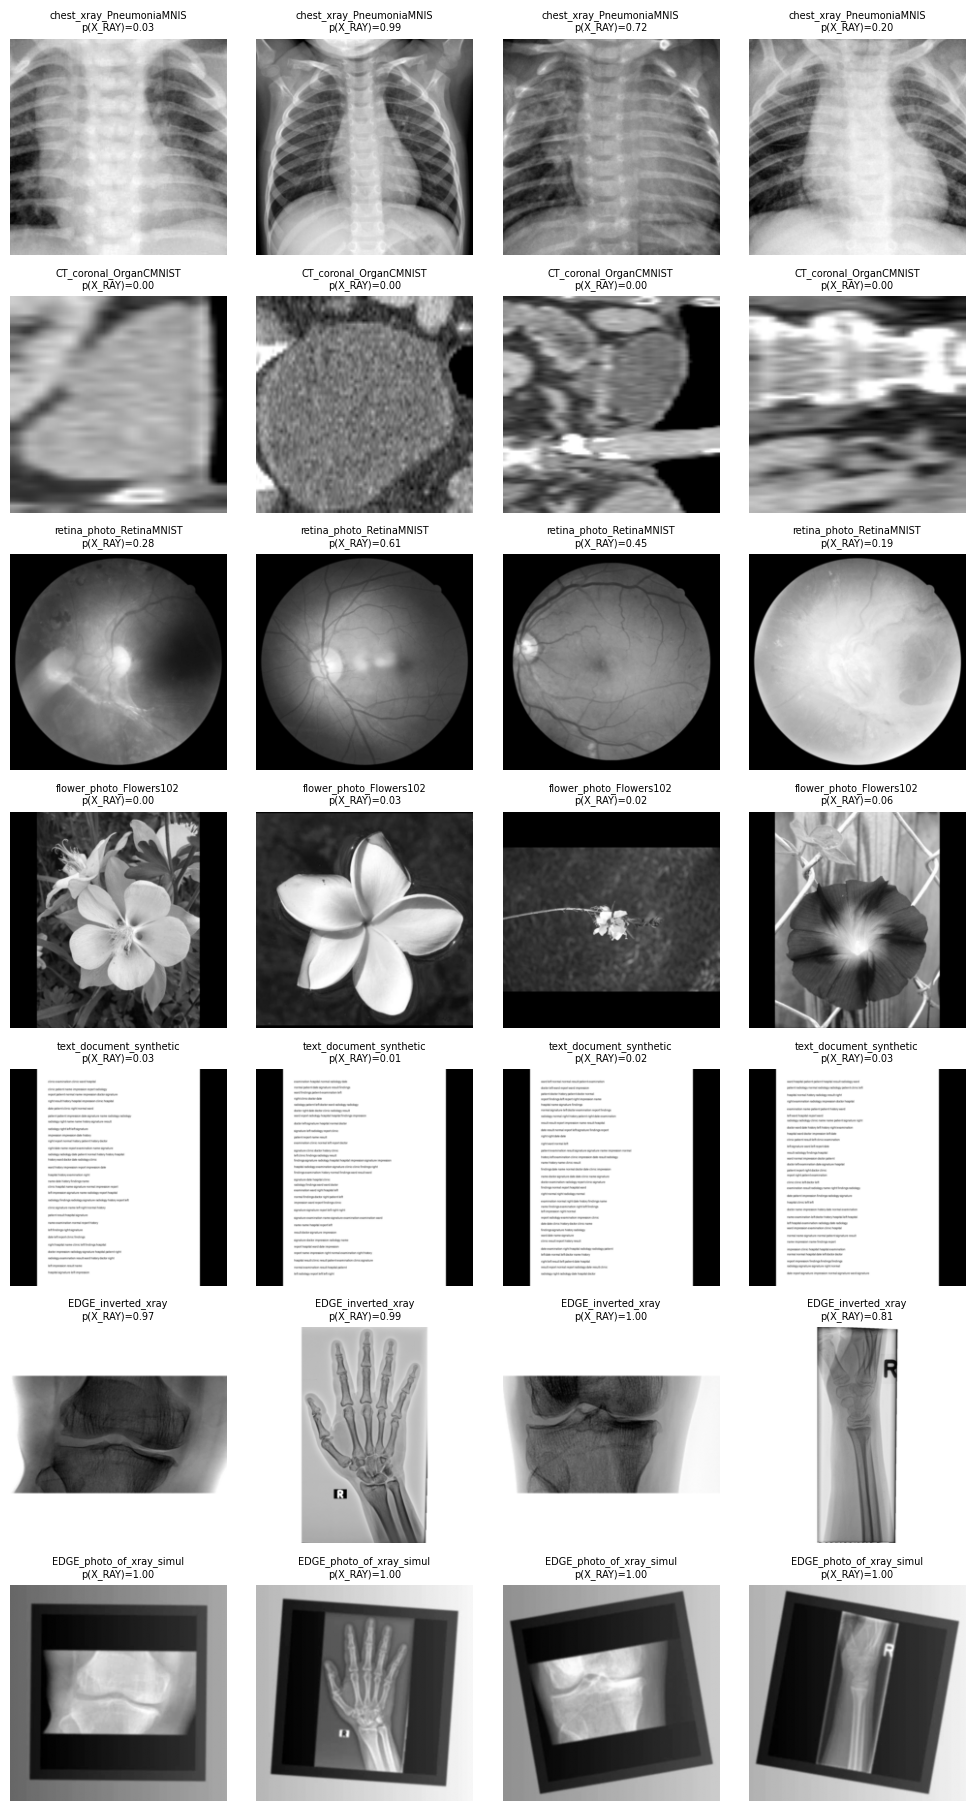

In [6]:
!pip install -q medmnist
import os, io, shutil, numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from torchvision import models, datasets
from medmnist import PneumoniaMNIST, RetinaMNIST, OrganCMNIST

device = 'cuda' if torch.cuda.is_available() else 'cpu'
out = '/content/drive/MyDrive/Research/outputs/model1'
if not os.path.exists('/content/cache_224.npz'):
    shutil.copy(f'{out}/cache_224.npz', '/content/cache_224.npz')
d = np.load('/content/cache_224.npz', allow_pickle=True)
rng = np.random.default_rng(7)

def to_224(im):
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.array(im).astype(np.float32); a = (a - a.min()) / (a.max() - a.min() + 1e-6) * 255
        im = Image.fromarray(a.astype(np.uint8))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    c = Image.new('L', (s, s), 0); c.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.array(c.resize((224, 224), Image.BILINEAR), dtype=np.uint8)

mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def prep(imgs):
    t = torch.from_numpy(imgs).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (t - mean) / std

model = models.mobilenet_v3_large()
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
model.load_state_dict(torch.load(f'{out}/mobilenetv3_model1_best.pt', map_location=device))
model = model.to(device).eval()

items = []
def add(group, expected, pil_list):
    for im in pil_list: items.append((group, expected, to_224(im)))

ds = PneumoniaMNIST(split='test', download=True, size=224, root='/content')
add('chest_xray_PneumoniaMNIST', 'X_RAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 60, replace=False)])
ds = OrganCMNIST(split='test', download=True, size=224, root='/content')
add('CT_coronal_OrganCMNIST', 'NON_XRAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 50, replace=False)])
ds = RetinaMNIST(split='test', download=True, size=224, root='/content')
add('retina_photo_RetinaMNIST', 'NON_XRAY', [Image.fromarray(ds.imgs[i]) for i in rng.choice(len(ds.imgs), 40, replace=False)])
fl = datasets.Flowers102('/content/flowers', split='test', download=True)
add('flower_photo_Flowers102', 'NON_XRAY', [fl[int(i)][0] for i in rng.choice(len(fl), 40, replace=False)])

words = ('patient report radiology hospital clinic name date result normal findings '
         'impression history examination left right signature doctor ward').split()
docs = []
for _ in range(20):
    im = Image.new('L', (600, 800), 255); dr = ImageDraw.Draw(im); yy = 40
    while yy < 760:
        dr.text((40, yy), ' '.join(rng.choice(words, rng.integers(4, 9))), fill=0); yy += int(rng.integers(18, 30))
    docs.append(im)
add('text_document_synthetic', 'NON_XRAY', docs)

X, y, split = d['X'], d['y'], d['split']
pick = rng.choice(np.where((split == 'test') & (y == 1))[0], 20, replace=False)
for j in pick:
    items.append(('EDGE_inverted_xray', 'unclear', 255 - X[j]))

def fake_phone_photo(img):
    xr = Image.fromarray(img).resize((300, 300)).convert('RGB')
    bg = tuple(int(v) for v in rng.integers(90, 200, 3))
    canvas = Image.new('RGB', (420, 420), bg)
    screen = Image.new('RGB', (340, 340), (20, 20, 20)); screen.paste(xr, (20, 20))
    canvas.paste(screen, (40, 40))
    canvas = canvas.rotate(float(rng.uniform(-12, 12)), resample=Image.BILINEAR, fillcolor=bg)
    a = np.array(canvas).astype(np.float32)
    a = np.clip(a * np.array([1.05, 1.0, 0.9]) + np.linspace(0, 60, 420)[None, :, None], 0, 255)
    im = Image.fromarray(a.astype(np.uint8)).filter(ImageFilter.GaussianBlur(1.2))
    buf = io.BytesIO(); im.save(buf, 'JPEG', quality=60); buf.seek(0)
    return Image.open(buf)
for j in pick:
    items.append(('EDGE_photo_of_xray_simulated', 'unclear', to_224(fake_phone_photo(X[j]))))

imgs = np.stack([it[2] for it in items])
with torch.no_grad():
    p = np.concatenate([torch.softmax(model(prep(imgs[k:k+64]).to(device)), 1)[:, 1].cpu().numpy()
                        for k in range(0, len(imgs), 64)])
res = pd.DataFrame({'group': [it[0] for it in items], 'expected': [it[1] for it in items], 'prob_xray': p})
res['predicted'] = np.where(res.prob_xray >= 0.5, 'X_RAY', 'NON_XRAY')
summary = res.groupby(['group', 'expected'], sort=False).agg(
    images=('predicted', 'size'),
    predicted_xray=('predicted', lambda s: int((s == 'X_RAY').sum())),
    mean_prob_xray=('prob_xray', 'mean')).reset_index()
summary['correct_%'] = np.where(summary.expected == 'X_RAY', summary.predicted_xray / summary.images * 100,
                        np.where(summary.expected == 'NON_XRAY',
                                 (summary.images - summary.predicted_xray) / summary.images * 100, np.nan)).round(1)
summary['mean_prob_xray'] = summary.mean_prob_xray.round(3)
print(summary.to_string(index=False))
summary.to_csv(f'{out}/unseen_test_summary.csv', index=False)
res.to_csv(f'{out}/unseen_test_predictions.csv', index=False)

groups = summary.group.tolist()
fig, axes = plt.subplots(len(groups), 4, figsize=(10, 2.6 * len(groups)))
for r, g in enumerate(groups):
    for c, i in enumerate(np.where(res.group == g)[0][:4]):
        ax = axes[r, c]; ax.imshow(imgs[i], cmap='gray'); ax.axis('off')
        ax.set_title(f'{g[:24]}\np(X_RAY)={p[i]:.2f}', fontsize=7)
plt.tight_layout(); plt.savefig(f'{out}/unseen_test_examples.png', dpi=130, bbox_inches='tight'); plt.show()

In [7]:
from medmnist import ChestMNIST
import os, random
from PIL import Image

dst = '/content/drive/MyDrive/Research/OTHER_XRAY/Chest_ChestMNIST'
os.makedirs(dst, exist_ok=True)
random.seed(42)
ds = ChestMNIST(split='train', download=True, size=128, root='/content')
for i in random.sample(range(len(ds.imgs)), 400):
    Image.fromarray(ds.imgs[i]).save(os.path.join(dst, f'chest_{i:06d}.png'))
print('Saved 400 chest X-rays to', dst)

100%|██████████| 1.43G/1.43G [08:26<00:00, 2.82MB/s]


Saved 400 chest X-rays to /content/drive/MyDrive/Research/OTHER_XRAY/Chest_ChestMNIST
